In [1]:
## PACKAGES
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
#import umap.umap_ as umap
import torch
import torch.nn.functional as F
import torchvision.transforms as transforms
import timm
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sn
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
import sys
sys.path.insert(1,'C:\Zmyfiles\codes\research\pyDeepInsight_SRT\pyDeepInsight_SRT\examples\Scripts')
from pyDeepInsightv3 import ImageTransformer

c:\Users\sheli\anaconda3\envs\SheliaWorkspace\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
##LOAD DATA
expr_file = r"..\Data\cptacvssmc\smc_labels.csv"
#expr_file = r"..\data\TvsN\TCGA_BRCA_NvT.csv"
#expr_file = r"..\data\Survival_TCGA_VS_Desmd\modified_TCGA_BRCA_log2.csv"
# expr1 = pd.read_csv(expr_file, encoding='utf-8', engine='python')
# expr=expr1.transpose()
# expr.columns=expr.iloc[0]
# X_all = expr.iloc[1:,1:-1].values
# X_all=X_all.astype(float)
# days= expr.iloc[1:,-1].values
# genes = expr.iloc[:,:-1].columns.to_numpy()
expr = pd.read_csv(expr_file, encoding='utf-8', engine='python')
expr=expr.transpose()
expr.columns=expr.iloc[0]
X = expr.iloc[1:,0:-1].values
X=X.astype(float)
Y = expr.iloc[1:,-1].values
genes = expr.iloc[:,:-1].columns.to_numpy()


In [2]:
## Data1
#expr_file1 = r"..\Data\TvsN\TCGA_BRCA_NvT.csv"
expr_file1 = r"..\Data\cptacvssmc\cptac_labels.csv"
#expr_file = r"..\data\Survival_TCGA_VS_Desmd\smc_labels.csv"
# expr1 = pd.read_csv(expr_file, encoding='utf-8', engine='python')
# expr=expr1.transpose()
# expr.columns=expr.iloc[0]
# X_all = expr.iloc[1:,1:-1].values
# X_all=X_all.astype(float)
# days= expr.iloc[1:,-1].values
# genes = expr.iloc[:,:-1].columns.to_numpy()
expr1 = pd.read_csv(expr_file1, encoding='utf-8', engine='python')
expr1=expr1.transpose()
expr1.columns=expr1.iloc[0]
X1 = expr1.iloc[1:,0:-1].values
X1=X1.astype(float)
Y1 = expr1.iloc[1:,-1].values
genes1 = expr1.iloc[:,:-1].columns.to_numpy()

##LOAD DATA2
#expr_file2 = r"..\Data\TvsN\GSE45498_NvT.csv"
expr_file2 = r"..\Data\cptacvssmc\smc_labels.csv"
#expr_file = r"..\data\Survival_TCGA_VS_Desmd\smc_labels.csv"
# expr1 = pd.read_csv(expr_file, encoding='utf-8', engine='python')
# expr=expr1.transpose()
# expr.columns=expr.iloc[0]
# X_all = expr.iloc[1:,1:-1].values
# X_all=X_all.astype(float)
# days= expr.iloc[1:,-1].values
# genes = expr.iloc[:,:-1].columns.to_numpy()
expr2 = pd.read_csv(expr_file2, encoding='utf-8', engine='python')
expr2=expr2.transpose()
expr2.columns=expr2.iloc[0]
X2 = expr2.iloc[1:,0:-1].values
X2=X2.astype(float)
Y2 = expr2.iloc[1:,-1].values
genes2 = expr2.iloc[:,:-1].columns.to_numpy()

In [ ]:
genes

In [ ]:
common_genes=[]
for i in genes1:
    for j in genes2:
        if i==j:
            common_genes.append(i)

print(common_genes)



In [ ]:

condition=np.isin(genes2,common_genes)
indexx=np.where(condition)[0]
print(indexx)



In [ ]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device,dtype=torch.long)

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

In [ ]:
X_new=[[0 if np.isnan(x) else x for x in row] for row in X]
np.array(X_new)

## DeepInsight Image Transformation
Convert data to image format using DeepInsight

In [3]:
from sklearn.decomposition import PCA, KernelPCA

In [4]:
# X_train, X_test, y_train, y_test = train_test_split(
#       X, Y, test_size=0.3, random_state=5, stratify=Y)

X_train, X_test, y_train, y_test = X1,X2,Y1,Y2

var_filter1 = X_train.var(0) >= np.percentile(X_train.var(0), 10., method='nearest')
var_filter2 = X_test.var(0) >= np.percentile(X_test.var(0), 10., method='nearest')

mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X_train[:, var_filter1])
X_test_norm = mms.fit_transform(X_test[:, var_filter2])

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

le_mapping = dict(zip(le.transform(le.classes_), le.classes_))
num_classes = np.unique(y_train_enc).size

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
net = timm.create_model('resnet50d', pretrained=True, num_classes=num_classes).to(device)
net = net.to(device)

batch_size=20
preprocess = transforms.Compose([
    transforms.ToTensor(),
    #transforms.Normalize(mean=net.default_cfg['mean'], std=net.default_cfg['std']),
])



In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    net.parameters(), 
    lr=1e-02,
    momentum=0.9,
)

In [ ]:
reducer=KernelPCA(n_components=2, kernel='rbf',gamma=.2)

pixel_size = (224,224)

it1 = ImageTransformer(
    feature_extractor=reducer,
    pixels=pixel_size)

it2 = ImageTransformer(
    feature_extractor=reducer,
    pixels=pixel_size)

it1.fit(X_train_norm, y=y_train, plot=False)
it2.fit(X_test_norm, y=y_test, plot=False)

X_train_img = it1.transform(X_train_norm)
X_test_img = it2.transform(X_test_norm)

In [ ]:

#defing the data loader
X_train_tensor = torch.stack([preprocess(img) for img in X_train_img]).float().to(device)
y_train_tensor = torch.from_numpy(y_train_enc).long().to(device)
trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

X_test_tensor = torch.stack([preprocess(img) for img in X_test_img]).float().to(device)
y_test_tensor = torch.from_numpy(y_test_enc).long().to(device)
testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)


##training the data using resnet:
net.train()
for epoch in range(40):
    for i, (inputs, labels) in enumerate(trainloader):
        clear_output(wait=True)
        #display(f"Epoch {epoch:03d}, batch {i:03d}")
        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        

###testing the data
test_predicted = np.empty(0)
test_true = np.empty(0)
#test_pred = np.empty(0)

net.eval()

with torch.no_grad():
    for i, (inputs, labels) in enumerate(testloader):
        pred = torch.max(net(inputs), dim=1)[1].cpu().detach().numpy()
        test_predicted = np.append(test_predicted, pred)
        test_true = np.append(test_true, labels.cpu().detach().numpy())


#test_pred = (test_predicted > 0.5).astype(int)        

net=net.to(torch.device('cpu'))
with torch.no_grad():
    y_hat = net(X_train_tensor.cpu())
train_predicted=torch.max(y_hat,1)[1]
 

print(f"The train accuracy was {accuracy_score(train_predicted, y_train_enc):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, test_true):.3f}")

        

In [ ]:
test_predicted = np.empty(0)
test_true = np.empty(0)
#test_pred = np.empty(0)
net.fc = nn.Linear(net.fc.in_features, 1)
net.eval()
net=net.to(torch.device('cpu'))


with torch.no_grad():
    for i, (inputs, labels) in enumerate(testloader):
        pred = torch.sigmoid(net(inputs.to(torch.device('cpu')))).cpu().detach().numpy()
        #pred = torch.max(net(inputs), dim=1)[1].cpu().detach().numpy()
        test_predicted = np.append(test_predicted, pred)
        test_true = np.append(test_true, labels.cpu().detach().numpy())


#test_pred = (test_predicted > 0.5).astype(int)        

net=net.to(torch.device('cpu'))
with torch.no_grad():
    y_hat = net(X_train_tensor.cpu())
train_predicted=torch.max(y_hat,1)[1]

In [ ]:
df = pd.DataFrame(test_true)
df.to_csv("true.csv", index=False, header=False)

In [ ]:
df = pd.DataFrame(test_predicted)
df.to_csv("pred_TCGA.csv", index=False, header=False)

SqueezeNet

In [5]:
from sklearn.manifold import TSNE
distance_metric = 'cosine'
reducer=KernelPCA(n_components=2, kernel='rbf',gamma=.1,random_state=42)
# reducer = TSNE(
#     n_components=2,
#     metric=distance_metric,
#     init='random',
#     learning_rate='auto',
#     n_jobs=-1)


pixel_size = (227,227)
it1 = ImageTransformer(
    feature_extractor=reducer,
    pixels=pixel_size)

it2 = ImageTransformer(
  feature_extractor=reducer,
    pixels=pixel_size)

it1.fit(X_train_norm, y=y_train, plot=False)
it2.fit(X_test_norm, y=y_test, plot=False)

X_train_img = it1.transform(X_train_norm)
X_test_img = it2.transform(X_test_norm)

In [6]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

import warnings; 
warnings.simplefilter('ignore')

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device
model = torchvision.models.squeezenet1_1(weights='DEFAULT')
model.classifier.append(nn.Flatten())
_ = model.classifier.append(nn.Linear(1000, num_classes))

In [8]:
preprocess = transforms.Compose([
    transforms.ToTensor()
])

In [9]:
X_train_tensor = torch.stack([preprocess(img) for img in X_train_img]).float()
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.stack([preprocess(img) for img in X_test_img]).float()
y_test_tensor = torch.from_numpy(le.transform(y_test))

batch_size = 20

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-04,
    #momentum=0.8,
    weight_decay=1e-05
)

In [10]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device,dtype=torch.long)

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 1.787
[20] loss: 0.661
[40] loss: 0.318
[60] loss: 0.031
[80] loss: 0.045
[99] loss: 0.001


In [11]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 1.000
The test accuracy was 0.217


In [ ]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    
    y_hat = model(X_test_tensor)
    y_prob_test = torch.sigmoid(y_hat,dim=1)
    test_predicted = (y_prob_test >= 0.5).int()


print(y_prob_test)

### **GRAD_CAM features**

In [12]:
from pyDeepInsightv3 import CAMFeatureSelector
cm_method='GradCAM'
camfs = CAMFeatureSelector(
    model=model,
    it=it2,
    cam_method=cm_method
)

In [24]:
fl_method = "max"
class_cam = camfs.calculate_class_activations(X_test_tensor, y_test_tensor, batch_size=100, flatten_method=fl_method)

### Select Class-Specific Features
Feature selection for each class is performed by identifying feature indicies mapped to coordinates of the CAM that pass the threshold.

In [25]:
fs_threshold = 0.5
feat_idx, feat_thr,coord= camfs.select_class_features(cams=class_cam, threshold=fs_threshold)

In [17]:
feat_thr[0]

array([0.5078364 , 0.52042324, 0.52042324, ..., 0.51175875, 0.52080733,
       0.52306947])

In [26]:
from pytorch_grad_cam.utils.image import show_cam_on_image
from matplotlib import pyplot as plt

def cam_image(X, y, cam, fs, threshold):
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(6,4),
                            constrained_layout=True)
    for cat in np.unique(y):
        cat_idx = np.where(y == cat)[0]
        X_cat = X[cat_idx,:,:,:].detach().mean(dim=0).cpu().numpy()
        cam_cat = cam[cat].copy()
        cam_cat[cam_cat <= threshold] = 0
        visualization = show_cam_on_image(
            np.transpose(X_cat, (1,2,0)),
            cam_cat,
            use_rgb=True
        )
        _ = axs[cat].imshow(visualization)
        axs[cat].text(0,0,le_mapping[cat],c="white",ha="left",va="top",weight="bold",size="x-large")
        axs[cat].text(227,227,f"{fs[cat].shape[0]} genes",c="white",ha="right",va="bottom",weight="bold",size="large")
        axs[cat].axis('off')
    return fig, axs

In [18]:
from pytorch_grad_cam.utils.image import show_cam_on_image
from matplotlib import pyplot as plt

def cam_image2(X, y, cam, fs, threshold):
    fig, axs = plt.subplots(ncols=2, nrows=2, figsize=(8, 4),
                            constrained_layout=True)
    for cat in np.unique(y):
        row = cat // 2
        col = cat % 2
        cat_idx = np.where(y == cat)[0]
        X_cat = X[cat_idx,:,:,:].detach().mean(dim=0).cpu().numpy()
        cam_cat = cam[cat].copy()
        cam_cat[cam_cat <= threshold] = 0
        visualization = show_cam_on_image(
            np.transpose(X_cat, (1,2,0)),
            cam_cat,
            use_rgb=True
        )
        _ = axs[row, col].imshow(visualization)
        axs[row, col].text(0,0,le_mapping[cat],c="white",ha="left",va="top",weight="bold",size="x-large")
        axs[row, col].text(227,227,f"{fs[cat].shape[0]} genes",c="white",ha="right",va="bottom",weight="bold",size="large")
        axs[row, col].axis('off')
    return fig, axs

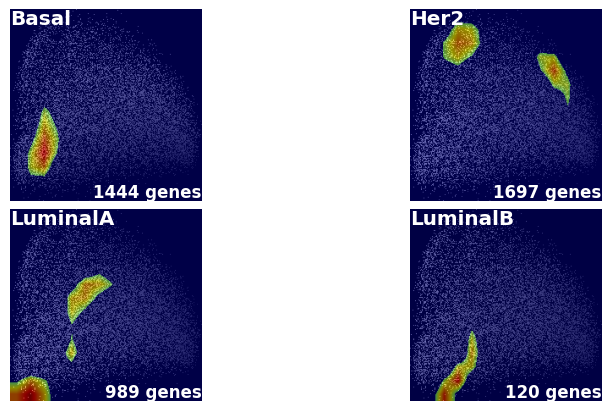

In [19]:
_ = cam_image2(X_train_tensor, y_train_tensor.detach().cpu().numpy(), class_cam, feat_idx, fs_threshold)

In [27]:
for cat, idx in feat_idx.items():
    feature_names = genes2[idx]
    print(f"{idx.shape[0]:5} features selected for {le_mapping[cat]:4}: {', '.join(feature_names[1:10])}...")
    

11765 features selected for Basal: C21orf119, TMEM237, AX746867, GIMAP2, NPRL2, TAS2R42, DYNLL1-AS1, HMGA1P7, CEACAM18...
 6300 features selected for Her2: RNF39, FAM103A1, NUMBL, FAM196B, CR627206, CCNT1, TLK1, RGPD4, RARA...
 3408 features selected for LuminalA: METTL21C, GMEB1, HCRTR1, NEO1, SH2D1A, SSX2B, DNM2, OR6C3, ABHD4...
 2891 features selected for LuminalB: AK302879, BC132949, BC013229, HBP1, BC051721, RNF219, PRKDC, SDHA, CMC4...


In [20]:
selected_features_by_class_np = {}  # Dictionary to hold features for each class

for cat, idx in feat_idx.items():
    feature_names = genes2[idx]
    class_name = le_mapping[cat]
    selected_features_by_class_np[class_name] = np.array(feature_names)  # Save as a list


In [29]:

import numpy as np

# Dictionary of PAM50 genes grouped by subtype
pam50_by_subtype = {
    "LuminalA": [
        "ESR1", "PGR", "BCL2", "BAG1", "MAPT", "MDM2", "MLPH", "NAT1", "SLC39A6", "FOXA1", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
    "LuminalB": [
        "MKI67", "CCNB1", "CCNE1", "CDC6", "CDC20", "CDC25A", "UBE2C", "MYBL2", "BIRC5", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
    "Her2": [
        "ERBB2", "GRB7", "FGFR4", "GPR160", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
    "Basal": [
        "KRT5", "KRT14", "KRT17", "EGFR", "FOXC1", "MIA", "PHGDH", "PTTG1", "MELK", "ACTR3B", "ANLN", "CDH3", "CENPF", "CEP55", "EXO1", "MYC", "NDC80", "NUF2", "ORC6L", 
        "RRM2", "TMEM45B", "TYMS", "UBE2T"
    ],
}

# Convert PAM50 genes to sets
pam50_by_subtype_sets = {
    subtype: set(genes) for subtype, genes in pam50_by_subtype.items()
}

# Assume selected_features_by_class_np = { "Luminal A": np.array([...]), ... }
comparison_results = {}

for subtype, selected_genes_np in selected_features_by_class_np.items():
    # Only compare this subtype with the corresponding PAM50 genes
    selected_genes = set(selected_genes_np.astype(str).tolist())
    if subtype in pam50_by_subtype_sets:
        pam_genes = pam50_by_subtype_sets[subtype]
        overlap = selected_genes & pam_genes
        comparison_results[subtype] = {
            "num_selected": len(selected_genes),
            "num_overlap": len(overlap),
            "overlap_genes": sorted(overlap)
        }

# 🖨️ Print the comparison
for subtype, result in comparison_results.items():
    print(f"\nSubtype: {subtype}")
    print(f"  Total selected genes: {result['num_selected']}")
    print(f"  Overlapping PAM50 genes: {result['num_overlap']}")
    print(f"  Genes: {', '.join(result['overlap_genes']) if result['overlap_genes'] else 'None'}")



Subtype: Basal
  Total selected genes: 1444
  Overlapping PAM50 genes: 1
  Genes: ANLN

Subtype: Her2
  Total selected genes: 1697
  Overlapping PAM50 genes: 1
  Genes: TMEM45B

Subtype: LuminalA
  Total selected genes: 989
  Overlapping PAM50 genes: 0
  Genes: None

Subtype: LuminalB
  Total selected genes: 120
  Overlapping PAM50 genes: 0
  Genes: None


In [ ]:
###For Saving the files

for key, array in selected_features_by_class_np.items():
    # Convert numpy array to DataFrame
    df = pd.DataFrame(array)
    
    # Save to Excel file named after the key
    filename = f"{key}.csv"
    df.to_csv(filename, index=False, header=False)  # You can customize index/header as needed
    
    print(f"Saved {filename}")

### GRAD-CAM with Ranking

In [ ]:
from pyDeepInsightv3 import CAMFeatureSelector

# Initialize Grad-CAM feature selector
camfs = CAMFeatureSelector(
    model=model,
    it=it2,
    cam_method='GradCAM'  # or 'GradCAM++', 'ScoreCAM', etc.
)



In [ ]:
# Calculate class activation maps for all classes
# `flatten_method='mean'` averages over spatial dimensions
class_cam = camfs.calculate_class_activations(
    X_test_tensor,
    y_test_tensor,
    batch_size=100,
    flatten_method='mean'
)

# class_cam is now a 2D NumPy array of shape (num_classes, num_features)
# Each row corresponds to a class; each column to a feature's Grad-CAM score



In [31]:
# Assuming class_cam shape is (num_classes, num_features)
# and genes2 is a numpy array of gene names, length = num_features
target_class=0
top_k = 10  # Number of top genes to show

# for class_idx in class_cam:
#     feature_scores = class_cam[class_idx]  # Scores for this class

feature_scores = feat_thr[target_class]
ranked_indices=feat_idx[target_class]
ranked_genes = genes2[ranked_indices]
sorted_indices = np.argsort(-feature_scores)
sorted_scores = feature_scores[sorted_indices]
sorted_genes = ranked_genes[sorted_indices]
sorted_index=ranked_indices[sorted_indices]

for i in range(top_k):
    # Map indices to gene names
    print(f"Rank {i+1}: Gene {sorted_genes[i]} - Score: {float(sorted_scores[i]):.4f}")

    # print(f"\nClass {class_idx} ({le_mapping[class_idx]}): Top {top_k} genes")
    # for i in range(top_k):
    #     

Rank 1: Gene BCL7B - Score: 1.0000
Rank 2: Gene NSF - Score: 1.0000
Rank 3: Gene FBXW11 - Score: 1.0000
Rank 4: Gene DHX38 - Score: 1.0000
Rank 5: Gene OR51L1 - Score: 1.0000
Rank 6: Gene SMIM17 - Score: 1.0000
Rank 7: Gene PPIF - Score: 1.0000
Rank 8: Gene FAM66E - Score: 1.0000
Rank 9: Gene BC062337 - Score: 1.0000
Rank 10: Gene SNX3 - Score: 0.9993


In [ ]:
feature_scores.shape